# dicompare tutorial: checking a multisite protocol in Python

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/astewartau/dicompare/blob/main/examples/dicompare_tutorial.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/astewartau/dicompare/main?labpath=examples%2Fdicompare_tutorial.ipynb)

[dicompare](https://github.com/astewartau/dicompare) checks that MRI acquisitions match a protocol, using only
the DICOM headers. It runs offline: nothing is uploaded anywhere.

This notebook walks through a typical multisite case from start to finish:

1. Make two small **synthetic** sessions: a *reference site* and a *second site* that drifted from the protocol.
2. Load a session into a pandas DataFrame.
3. Build a protocol **schema** from the reference site.
4. **Map** the second site's acquisitions to the schema, and read the mapping's cost and confidence.
5. **Check** the second site with `check_session()`.
6. Show the results as a table and charts.
7. Allow for differences you accept between sites (tolerances).
8. Check against a published guideline from dicompare's schema library.
9. Save a JSON report, and do the same from the command line for pipelines.

All the data here is made up: a numerical phantom with a few slices per volume. No real or patient data is used.

**Requirements:** `dicompare`, plus `matplotlib` and `jinja2` (for the plots and the styled table). The next
cell installs them if they are missing, for example on Colab or Binder.

In [1]:
import importlib.util

missing = [m for m in ("matplotlib", "jinja2") if importlib.util.find_spec(m) is None]
try:
    from dicompare import check_session  # new: install from GitHub until a PyPI release has it
except ImportError:
    missing.append("git+https://github.com/astewartau/dicompare")
if missing:
    %pip install -q {" ".join(missing)}

In [2]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import dicompare
from dicompare import (
    assign_acquisition_and_run_numbers,
    build_schema,
    check_session,
    load_bundled_schema,
    load_dicom_session,
    make_json_serializable,
    map_to_json_reference,
)
from dicompare.check import mapping_confidence

%config InlineBackend.figure_format = "png"
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.max_colwidth", 60)

## 1. Make synthetic DICOMs for two sites

You would normally point dicompare at real DICOM folders. To keep this notebook self-contained, the next cell
writes small fake ones with [pydicom](https://pydicom.github.io/). Each file has a realistic MR header and a
64 × 64 phantom image. You don't need to read this cell closely; it just writes files.

(dicompare also has `generate_test_dicoms_from_schema()`, which makes test DICOMs from a schema's example values.
Here we write the headers by hand so we can build whole sessions with deliberate differences.)

In [3]:
import pydicom
from pydicom.dataset import Dataset, FileMetaDataset
from pydicom.uid import ExplicitVRLittleEndian, MRImageStorage, generate_uid

DATA = Path("dicompare_tutorial_data")


def phantom(n, slice_index, nslices):
    """A head-shaped ellipsoid with two 'ventricles', scaled to 12-bit."""
    y, x = np.mgrid[-1:1:n * 1j, -1:1:n * 1j]
    z = (slice_index - (nslices - 1) / 2) / nslices * 0.4
    head = (x / 0.75) ** 2 + (y / 0.9) ** 2 + z ** 2
    img = np.where(head < 1.0, 0.55, 0.0)
    img = np.where(head < 0.8, 0.8, img)
    ventricles = ((np.abs(x) - 0.12) / 0.08) ** 2 + (y / 0.3) ** 2
    img = np.where((head < 0.8) & (ventricles < 1.0), 0.35, img)
    return (img * 4000).astype("<u2")


def write_series(site_dir, protocol, params, pixel_spacing, echo_times=(None,), image_types=("M",),
                 nslices=2, n=64):
    """Write one acquisition: one file per image type (magnitude/phase) x echo x slice."""
    out = Path(site_dir) / protocol
    out.mkdir(parents=True, exist_ok=True)
    site = Path(site_dir).name
    for itype in image_types:
        series_uid = generate_uid(entropy_srcs=[site, protocol, itype])
        for echo, te in enumerate(echo_times, start=1):
            for k in range(nslices):
                ds = Dataset()
                ds.SOPClassUID = MRImageStorage
                ds.SOPInstanceUID = generate_uid(entropy_srcs=[site, protocol, itype, str(echo), str(k)])
                ds.StudyInstanceUID = generate_uid(entropy_srcs=[site])
                ds.SeriesInstanceUID = series_uid
                ds.Modality, ds.Manufacturer, ds.MagneticFieldStrength = "MR", "SIEMENS", 3
                ds.PatientName, ds.PatientID = "Synthetic^Phantom", f"PHANTOM-{site}"
                ds.StudyDate = ds.SeriesDate = "20260101"
                ds.SeriesTime = "090000"
                ds.ProtocolName = ds.SeriesDescription = protocol
                ds.InstanceNumber = (echo - 1) * nslices + k + 1
                ds.ImageType = ["ORIGINAL", "PRIMARY", itype]
                for key, value in params.items():
                    setattr(ds, key, value)
                if te is not None:
                    ds.EchoTime, ds.EchoNumbers = te, echo
                ds.PixelSpacing = [pixel_spacing, pixel_spacing]
                ds.ImageOrientationPatient = [1, 0, 0, 0, 1, 0]
                ds.ImagePositionPatient = [0, 0, k * params["SliceThickness"]]
                ds.SamplesPerPixel, ds.PhotometricInterpretation = 1, "MONOCHROME2"
                ds.Rows = ds.Columns = n
                ds.BitsAllocated, ds.BitsStored, ds.HighBit, ds.PixelRepresentation = 16, 12, 11, 0
                ds.PixelData = phantom(n, k, nslices).tobytes()
                ds.file_meta = FileMetaDataset()
                ds.file_meta.MediaStorageSOPClassUID = ds.SOPClassUID
                ds.file_meta.MediaStorageSOPInstanceUID = ds.SOPInstanceUID
                ds.file_meta.TransferSyntaxUID = ExplicitVRLittleEndian
                path = out / f"{itype}_echo{echo}_slice{k + 1}.dcm"
                if int(pydicom.__version__.split(".")[0]) >= 3:
                    pydicom.dcmwrite(path, ds, enforce_file_format=True)
                else:
                    ds.is_little_endian, ds.is_implicit_VR = True, False
                    pydicom.dcmwrite(path, ds, write_like_original=False)

The protocol has three acquisitions: a T1-weighted MPRAGE, a five-echo GRE for QSM (magnitude and phase), and a
T2-weighted FLAIR. The **reference site** (`site_A`) runs it exactly. The **second site** (`site_B`) has drifted
in ways that are common in practice:

| Acquisition | Reference site | Second site |
|---|---|---|
| T1w MPRAGE | TR 2400 ms, TE 2.14 ms, 0.8 mm isotropic | TR 2300 ms, TE 2.98 ms, 1 mm isotropic |
| QSM multi-echo GRE | 1 mm isotropic | 1 × 1 × 2 mm (thicker slices) |
| T2w FLAIR | present | **missing** |

The second site also names its protocols differently, so dicompare has to work out which is which.

In [4]:
common = dict(MRAcquisitionType="3D", NumberOfAverages=1, PixelBandwidth=200, ReceiveCoilName="HeadNeck_64")
t1 = dict(common, SeriesNumber=2, ScanningSequence=["GR", "IR"], RepetitionTime=2400, EchoTime=2.14,
          InversionTime=1000, FlipAngle=8, SliceThickness=0.8)
qsm = dict(common, SeriesNumber=3, ScanningSequence="GR", RepetitionTime=30, FlipAngle=12, SliceThickness=1.0)
flair = dict(common, SeriesNumber=4, ScanningSequence=["SE", "IR"], RepetitionTime=5000, EchoTime=390,
             InversionTime=1800, FlipAngle=120, SliceThickness=1.0)
qsm_echo_times = [4.0, 10.0, 16.0, 22.0, 28.0]

site_a_dir, site_b_dir = DATA / "site_A", DATA / "site_B"

# Reference site: the protocol as intended
write_series(site_a_dir, "T1w_MPR", t1, pixel_spacing=0.8)
write_series(site_a_dir, "QSM_ME_GRE", qsm, pixel_spacing=1.0, echo_times=qsm_echo_times, image_types=("M", "P"))
write_series(site_a_dir, "T2w_FLAIR", flair, pixel_spacing=1.0)

# Second site: different TR/TE and voxel size, thicker QSM slices, no FLAIR
write_series(site_b_dir, "t1_mprage_sag", dict(t1, RepetitionTime=2300, EchoTime=2.98, SliceThickness=1.0),
             pixel_spacing=1.0)
write_series(site_b_dir, "gre_qsm_5echo", dict(qsm, SliceThickness=2.0), pixel_spacing=1.0,
             echo_times=qsm_echo_times, image_types=("M", "P"))

for site_dir in (site_a_dir, site_b_dir):
    for acq_dir in sorted(site_dir.iterdir()):
        print(f"{acq_dir}: {len(list(acq_dir.glob('*.dcm')))} files")

dicompare_tutorial_data/site_A/QSM_ME_GRE: 20 files
dicompare_tutorial_data/site_A/T1w_MPR: 2 files
dicompare_tutorial_data/site_A/T2w_FLAIR: 2 files
dicompare_tutorial_data/site_B/gre_qsm_5echo: 20 files
dicompare_tutorial_data/site_B/t1_mprage_sag: 2 files


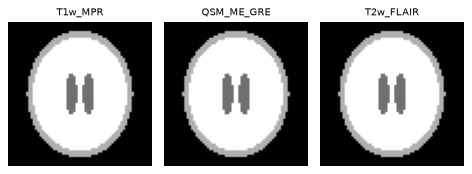

In [5]:
# A quick look at the (fake) images
fig, axes = plt.subplots(1, 3, figsize=(6, 2.2))
for ax, name in zip(axes, ["T1w_MPR", "QSM_ME_GRE", "T2w_FLAIR"]):
    path = sorted((site_a_dir / name).glob("*.dcm"))[0]
    ax.imshow(pydicom.dcmread(path).pixel_array, cmap="gray")
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.tight_layout()

## 2. Load a session

`load_dicom_session()` reads every DICOM file under a folder (headers only, no pixel data) and returns a pandas
DataFrame with **one row per file** and one column per DICOM field.

In [6]:
site_a = load_dicom_session(session_dir=str(site_a_dir))
site_b = load_dicom_session(session_dir=str(site_b_dir))
print(f"site_A: {site_a.shape[0]} files x {site_a.shape[1]} fields")

site_a[["ProtocolName", "ImageType", "EchoTime", "RepetitionTime", "FlipAngle", "SliceThickness",
        "PixelSpacing"]].sort_values(["ProtocolName", "ImageType", "EchoTime"]).head(8)

site_A: 24 files x 41 fields


,ProtocolName,ImageType,EchoTime,RepetitionTime,FlipAngle,SliceThickness,PixelSpacing
7,QSM_ME_GRE,"(ORIGINAL, PRIMARY, M)",4.0,30.0,12.0,1.0,"(1.0, 1.0)"
12,QSM_ME_GRE,"(ORIGINAL, PRIMARY, M)",4.0,30.0,12.0,1.0,"(1.0, 1.0)"
18,QSM_ME_GRE,"(ORIGINAL, PRIMARY, M)",10.0,30.0,12.0,1.0,"(1.0, 1.0)"
17,QSM_ME_GRE,"(ORIGINAL, PRIMARY, M)",10.0,30.0,12.0,1.0,"(1.0, 1.0)"
16,QSM_ME_GRE,"(ORIGINAL, PRIMARY, M)",16.0,30.0,12.0,1.0,"(1.0, 1.0)"
5,QSM_ME_GRE,"(ORIGINAL, PRIMARY, M)",16.0,30.0,12.0,1.0,"(1.0, 1.0)"
14,QSM_ME_GRE,"(ORIGINAL, PRIMARY, M)",22.0,30.0,12.0,1.0,"(1.0, 1.0)"
15,QSM_ME_GRE,"(ORIGINAL, PRIMARY, M)",22.0,30.0,12.0,1.0,"(1.0, 1.0)"


dicompare groups the files into **acquisitions** (one per protocol run) and, within each, **series** (for
example each echo and image type of the QSM scan). `assign_acquisition_and_run_numbers()` adds those columns.
`check_session()` does this for you, but it is useful to see:

In [7]:
site_a_grouped = assign_acquisition_and_run_numbers(site_a)
(site_a_grouped.groupby(["Acquisition", "ProtocolName"])
    .agg(files=("DICOM_Path", "size"), echoes=("EchoTime", "nunique"))
    .reset_index())

,Acquisition,ProtocolName,files,echoes
0,acq-qsmmegre,QSM_ME_GRE,20,5
1,acq-t1wmpr,T1w_MPR,2,1
2,acq-t2wflair,T2w_FLAIR,2,1


## 3. Build a schema from the reference site

A **schema** is a JSON description of the protocol: for each acquisition, the fields that must have a given
value. `build_schema()` makes one from a session, using the fields that define how a scan is acquired (TR, TE,
flip angle, slice thickness, ...). Fields that differ between the series of an acquisition, like the QSM echo
times, go into per-series entries.

In a real study you would build the schema once from a pilot scan at the lead site, review it (the
[dicompare web app](https://dicompare.neurodesk.org/) has an editor), and share the JSON file with every site.

In [8]:
schema = build_schema(site_a)
schema["name"] = "Multisite protocol (from site_A)"

for acq_name, acq in schema["acquisitions"].items():
    fields = [f["field"] for f in acq["fields"]]
    print(f"{acq_name}: {len(fields)} fields, {len(acq['series'])} series -> {', '.join(fields)}")

schema_path = Path("site_A_schema.json")
schema_path.write_text(json.dumps(make_json_serializable(schema), indent=2))
print(f"\nSaved {schema_path}")

acq-qsmmegre: 8 fields, 10 series -> MRAcquisitionType, SliceThickness, RepetitionTime, FlipAngle, NumberOfAverages, MagneticFieldStrength, PixelBandwidth, ReceiveCoilName
acq-t1wmpr: 11 fields, 0 series -> MRAcquisitionType, SliceThickness, RepetitionTime, EchoTime, InversionTime, FlipAngle, NumberOfAverages, MagneticFieldStrength, PixelBandwidth, ReceiveCoilName, ImageType
acq-t2wflair: 11 fields, 0 series -> MRAcquisitionType, SliceThickness, RepetitionTime, EchoTime, InversionTime, FlipAngle, NumberOfAverages, MagneticFieldStrength, PixelBandwidth, ReceiveCoilName, ImageType

Saved site_A_schema.json


In [9]:
# One acquisition's entry, as it appears in the JSON file
t1_entry = schema["acquisitions"]["acq-t1wmpr"]
print(json.dumps(make_json_serializable(t1_entry["fields"][:4]), indent=2))

[
  {
    "field": "MRAcquisitionType",
    "tag": "0018,0023",
    "value": "3D",
    "fieldType": "standard"
  },
  {
    "field": "SliceThickness",
    "tag": "0018,0050",
    "value": 0.8,
    "fieldType": "standard"
  },
  {
    "field": "RepetitionTime",
    "tag": "0018,0080",
    "value": 2400.0,
    "fieldType": "standard"
  },
  {
    "field": "EchoTime",
    "tag": "0018,0081",
    "value": 2.14,
    "fieldType": "standard"
  }
]


## 4. Map the second site's acquisitions to the schema

The second site called its scans `t1_mprage_sag` and `gre_qsm_5echo`, so dicompare can't match them by name.
Instead it scores every pair of (schema acquisition, input acquisition) by how far the fields differ. That
score is the **cost**: 0 means every field matches, and each mismatched field adds to it, more for bigger
differences. It then picks the one-to-one assignment with the lowest total cost.

The cost is summarised as a **confidence**: `exact` (cost 0), `high` (below 5), `medium` (below 20) or `low`.
A low-confidence match is worth a look: it may be the right scan with many deviations, or the wrong scan.
When the schema has more acquisitions than the session, the ones left over are **unmapped**.

`check_session()` does all of this automatically. Here we call the mapping step by hand to see it:

In [10]:
site_b_grouped = assign_acquisition_and_run_numbers(site_b)
mapping, cost_details = map_to_json_reference(site_b_grouped, schema, return_costs=True)

pd.DataFrame([
    {"schema acquisition": ref,
     "site_B acquisition": mapping.get(ref, "(unmapped)"),
     "cost": cost_details["assigned_costs"].get(ref),
     "confidence": mapping_confidence(cost_details["assigned_costs"][ref]) if ref in mapping else None}
    for ref in schema["acquisitions"]
])

,schema acquisition,site_B acquisition,cost,confidence
0,acq-qsmmegre,acq-greqsm5echo,1.00,high
1,acq-t1wmpr,acq-t1mpragesag,11.04,medium
2,acq-t2wflair,(unmapped),NaN,NaN


In [11]:
# The full cost matrix: every schema acquisition against every input acquisition
pd.DataFrame(cost_details["cost_matrix"], index=cost_details["ref_acq_list"],
             columns=cost_details["input_acq_list"]).round(1)

,acq-greqsm5echo,acq-t1mpragesag
acq-qsmmegre,1.0,17.0
acq-t1wmpr,45.2,11.0
acq-t2wflair,51.0,40.0


The QSM scan matches with high confidence (only the slice thickness differs), and the T1 with medium confidence
(TR, TE and slice thickness differ). The FLAIR has nothing to match, so it is unmapped.

If the automatic mapping is ever wrong, pass your own to `check_session(..., mapping={"schema acq": "input acq"})`.
Schema acquisitions you leave out of it are reported as unmapped.

## 5. Check compliance with `check_session()`

`check_session()` takes a session (a folder path or a DataFrame) and a schema (a JSON path or a dict), maps the
acquisitions, and checks every field. It returns a DataFrame with **one row per check**:

- `reference_acquisition`, `input_acquisition`, `mapping_cost`, `mapping_confidence`: which scan was checked
  against which schema entry, and how sure the match is;
- `field`, `series`, `expected`, `value`, `message`: what was checked and what was found;
- `status`: `ok`, `error` (fails), `warning`, `na` (field not found), or `unmapped` (one row per schema
  acquisition with no matching scan).

In [12]:
results = check_session(site_b, schema_path)
results.head()

,reference_acquisition,input_acquisition,mapping_cost,mapping_confidence,field,series,rule_name,value,expected,message,passed,status
0,acq-qsmmegre,acq-greqsm5echo,1.0,high,MRAcquisitionType,None,None,[3D],3D,Passed.,True,ok
1,acq-qsmmegre,acq-greqsm5echo,1.0,high,SliceThickness,None,None,[2.0],1.0,Expected 1.0 but got 2.0,False,error
2,acq-qsmmegre,acq-greqsm5echo,1.0,high,RepetitionTime,None,None,[30.0],30.0,Passed.,True,ok
3,acq-qsmmegre,acq-greqsm5echo,1.0,high,FlipAngle,None,None,[12.0],12.0,Passed.,True,ok
4,acq-qsmmegre,acq-greqsm5echo,1.0,high,NumberOfAverages,None,None,[1.0],1.0,Passed.,True,ok


In [13]:
pd.crosstab(results["reference_acquisition"], results["status"], margins=True)

status,error,ok,unmapped,All
reference_acquisition,,,,
acq-qsmmegre,1,17,0,18
acq-t1wmpr,3,8,0,11
acq-t2wflair,0,0,1,1
All,4,25,1,30


## 6. Look at the results

The DataFrame is the full record. A few views make it quicker to read.

### A styled table of everything that did not pass

In [14]:
STATUS_COLOURS = {"ok": "#d4edda", "warning": "#fff3cd", "error": "#f8d7da", "na": "#e2e3e5",
                  "unmapped": "#e8dff5"}
STATUS_ICONS = {"ok": "✅ ok", "warning": "⚠️ warning", "error": "❌ error", "na": "➖ n/a",
                "unmapped": "❓ unmapped"}


def first(v):
    # Values come back as lists (one entry per distinct value in the data)
    return v[0] if isinstance(v, (list, tuple)) and len(v) == 1 else v


def show_results(df):
    table = df.assign(
        status=df["status"].map(STATUS_ICONS),
        value=df["value"].map(first),
    )[["reference_acquisition", "input_acquisition", "mapping_confidence", "field", "series",
       "expected", "value", "status", "message"]]
    colour = df["status"].map(STATUS_COLOURS)
    return (table.style
            .apply(lambda col: [f"background-color: {c}" for c in colour], subset=["status"])
            .format(na_rep="")
            .hide(axis="index"))


show_results(results[results["status"] != "ok"])

reference_acquisition,input_acquisition,mapping_confidence,field,series,expected,value,status,message
acq-qsmmegre,acq-greqsm5echo,high,SliceThickness,,1.000000,2.000000,❌ error,Expected 1.0 but got 2.0
acq-t1wmpr,acq-t1mpragesag,medium,SliceThickness,,0.800000,1.000000,❌ error,Expected 0.8 but got 1.0
acq-t1wmpr,acq-t1mpragesag,medium,RepetitionTime,,2400.000000,2300.000000,❌ error,Expected 2400.0 but got 2300.0
acq-t1wmpr,acq-t1mpragesag,medium,EchoTime,,2.140000,2.980000,❌ error,Expected 2.14 but got 2.98
acq-t2wflair,,,,,,,❓ unmapped,No input acquisition mapped to reference acquisition 'acq-t2wflair'


### A per-acquisition summary

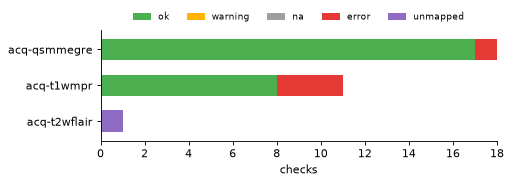

In [15]:
order = ["ok", "warning", "na", "error", "unmapped"]
counts = (pd.crosstab(results["reference_acquisition"], results["status"])
          .reindex(columns=order, fill_value=0))

ax = counts.plot.barh(stacked=True, figsize=(6.5, 2.4), width=0.6,
                      color=["#4caf50", "#ffb300", "#9e9e9e", "#e53935", "#8e6cc4"])
ax.set_xlabel("checks")
ax.set_ylabel("")
ax.invert_yaxis()
ax.legend(ncol=5, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()

### Expected vs actual for the failed fields

For numeric fields it helps to see how far off each value is, as a percentage of the expected value:

,expected,actual,difference (%)
check,,,
acq-qsmmegre SliceThickness,1.0,2.00,100.00
acq-t1wmpr SliceThickness,0.8,1.00,25.00
acq-t1wmpr RepetitionTime,2400.0,2300.00,-4.17
acq-t1wmpr EchoTime,2.14,2.98,39.25


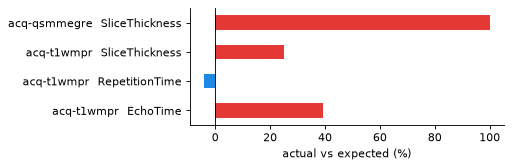

In [16]:
failed = results[results["status"] == "error"].copy()
failed["actual"] = failed["value"].map(first)
failed = failed[pd.to_numeric(failed["expected"], errors="coerce").notna()
                & pd.to_numeric(failed["actual"], errors="coerce").notna()]
failed["difference (%)"] = 100 * (failed["actual"].astype(float) - failed["expected"].astype(float)) \
    / failed["expected"].astype(float)
failed["check"] = failed["reference_acquisition"] + "  " + failed["field"]
display(failed[["check", "expected", "actual", "difference (%)"]].set_index("check").round(2))

ax = failed.plot.barh(x="check", y="difference (%)", legend=False, figsize=(6.5, 2.2),
                      color=np.where(failed["difference (%)"] > 0, "#e53935", "#1e88e5"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("actual vs expected (%)")
ax.set_ylabel("")
ax.invert_yaxis()
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()

## 7. Allow for differences you accept

Not every difference matters. If your study decides that a TR within ±150 ms is fine, add a `tolerance` to that
field in the schema. Other constraints work the same way: `min`/`max` for a range, `contains` for text.
Here we relax the T1's TR and check again:

In [17]:
import copy

relaxed = copy.deepcopy(schema)
for field in relaxed["acquisitions"]["acq-t1wmpr"]["fields"]:
    if field["field"] == "RepetitionTime":
        field["tolerance"] = 150

relaxed_results = check_session(site_b, relaxed)
t1_failures = lambda df: df[(df["reference_acquisition"] == "acq-t1wmpr") & (df["status"] == "error")]["field"]
print("T1 failures before:", ", ".join(t1_failures(results)))
print("T1 failures after: ", ", ".join(t1_failures(relaxed_results)))

T1 failures before: SliceThickness, RepetitionTime, EchoTime
T1 failures after:  SliceThickness, EchoTime


## 8. Check against a published guideline

dicompare ships a library of schemas for published protocols and guidelines. Unlike a schema built from one
site, these often contain **rules**: small Python checks that encode the guideline's reasoning (for example,
"echo times are evenly spaced" or "voxels are isotropic").

In [18]:
dicompare.list_bundled_schemas()

['ASL_Clinical_Guidelines_v1.0.json',
 'Generic_Spine_v1.0.json',
 'MS_CMSC_Guidelines_v1.0.json',
 'MY-RADS_Myeloma_v1.0.json',
 'QSM_Consensus_Guidelines_v1.0.json',
 'UK_Biobank_v1.0.json',
 'UMMS_Ping_v1.0.json',
 'abcd_schema_cleaned.json',
 'hcp_schema.json']

In [19]:
_, qsm_guideline, _ = load_bundled_schema("QSM_Consensus_Guidelines_v1.0.json")
(qsm_ref,) = qsm_guideline["acquisitions"]  # this schema has a single acquisition
print(qsm_ref)

# The guideline describes only the QSM scan, so map it explicitly to each site's QSM acquisition
guideline = pd.concat([
    check_session(site_a, qsm_guideline, mapping={qsm_ref: "acq-qsmmegre"}).assign(site="site_A"),
    check_session(site_b, qsm_guideline, mapping={qsm_ref: "acq-greqsm5echo"}).assign(site="site_B"),
])
(guideline.assign(check=guideline["rule_name"].fillna(guideline["field"]))
    .pivot(index="check", columns="site", values="status"))

Quantitative Susceptibility Mapping (QSM)


site,site_A,site_B
check,,
Ernst Flip Angle,ok,ok
Isotropic Voxels,ok,error
MRAcquisitionType,ok,ok
Matching Magnitude/Phase Slices,ok,ok
Multi-echo Validation,ok,ok
Readout Bandwidth,ok,ok
Short First Echo,ok,ok
TE Close to T2*,ok,ok
Uniform Echo Spacing,ok,ok


In [20]:
show_results(guideline[guideline["status"] != "ok"])

reference_acquisition,input_acquisition,mapping_confidence,field,series,expected,value,status,message
Quantitative Susceptibility Mapping (QSM),acq-greqsm5echo,exact,"PixelSpacing, SliceThickness",,Use isotropic voxels.,"{'PixelSpacing': [(1.0, 1.0)], 'SliceThickness': [2.0], 'Count': [20]}",❌ error,"Voxels not isotropic (tolerance 0.1 mm). PixelSpacing (1.0, 1.0), SliceThickness 2.0."
Quantitative Susceptibility Mapping (QSM),acq-greqsm5echo,exact,"PixelSpacing, SliceThickness",,Use a combined voxel size of at most 1 mm³ to reduce partial volume-related estimation errors.,"{'PixelSpacing': [(1.0, 1.0)], 'SliceThickness': [2.0], 'Count': [20]}",❌ error,Voxel size should be <= 1 mm³. Got 2.00 mm³.


The reference site meets the guideline. The second site's 2 mm slices break two of its rules: the voxels are
no longer isotropic, and the voxel volume is above the recommended limit.

## 9. Save a report, and run the same check from the command line

The results DataFrame can be saved like any other (`results.to_csv(...)`). To save the same JSON report that
`dicompare check` writes:

In [21]:
report_path = Path("site_B_report.json")
report_path.write_text(json.dumps(make_json_serializable(results.to_dict(orient="records")), indent=2))
print(f"Saved {report_path} ({len(results)} records)")
print(json.dumps(json.loads(report_path.read_text())[-1], indent=2))  # the unmapped FLAIR

Saved site_B_report.json (30 records)
{
  "reference_acquisition": "acq-t2wflair",
  "input_acquisition": null,
  "mapping_cost": null,
  "mapping_confidence": null,
  "field": null,
  "series": null,
  "rule_name": null,
  "value": null,
  "expected": null,
  "message": "No input acquisition mapped to reference acquisition 'acq-t2wflair'",
  "passed": false,
  "status": "unmapped"
}


In a pipeline you may not want Python at all. The `dicompare check` command does the same as `check_session()`
and **exits with status 1** if any check fails or an acquisition is unmapped (0 otherwise), so a script can stop
or flag a session:

```bash
dicompare check dicompare_tutorial_data/site_B site_A_schema.json site_B_report.json --auto-yes
echo "exit status: $?"
```

`--auto-yes` accepts the automatic mapping instead of asking. Checking many sessions is a shell loop:

```bash
for session in sessions/*/; do
    name=$(basename "$session")
    dicompare check "$session" protocol.json "reports/$name.json" --auto-yes > "reports/$name.txt" \
        || echo "$name: not compliant"
done
```

The next cell runs the first command from Python, so it works wherever this notebook does:

In [22]:
cli = subprocess.run(
    [sys.executable, "-m", "dicompare.cli.main", "check", str(site_b_dir), str(schema_path),
     "site_B_report_cli.json", "--auto-yes"],
    capture_output=True, text=True,
)
print(cli.stdout)
print("exit status:", cli.returncode)


Acquisition Mapping:
--------------------------------------------------------------------------------
  Reference                           Input                       Cost  Confidence
--------------------------------------------------------------------------------
  acq-qsmmegre                        acq-greqsm5echo              1.0  high
  acq-t1wmpr                          acq-t1mpragesag             11.0  medium
  acq-t2wflair                        (unmapped)                    --  --
--------------------------------------------------------------------------------

=== acq-qsmmegre  ->  acq-greqsm5echo ===
  17 passed, 1 failed (18 total)

  [FAIL] SliceThickness
         expected: 1.0
         got:      [2.0]
         Expected 1.0 but got 2.0

=== acq-t1wmpr  ->  acq-t1mpragesag ===
  8 passed, 3 failed (11 total)

  [FAIL] SliceThickness
         expected: 0.8
         got:      [1.0]
         Expected 0.8 but got 1.0
  [FAIL] RepetitionTime
         expected: 2400.0
        

## Next steps

- Use your own data: `check_session("/path/to/session", "protocol.json")`. A session can also be a DataFrame
  from `load_dicom_session()`, so you can filter or fix it first.
- Edit schemas, add rules and browse the library in the [dicompare web app](https://dicompare.neurodesk.org/),
  which runs the same package in your browser without uploading anything.
- See the [README](https://github.com/astewartau/dicompare#python-api) for the rest of the Python API, and
  `dicompare --help` for the command line.

To remove the files this notebook wrote, delete `dicompare_tutorial_data/`, `site_A_schema.json`,
`site_B_report.json` and `site_B_report_cli.json`.